# 3. Оценка и исследовательский отчёт

Оценка моделей выполняется на GPU-сервере. `RUN_NAME` и `CHECKPOINT_KIND` задают опыт и тип checkpoint. Каждый опыт оценивается после перезапуска kernel по одному протоколу.

Метрики WikiWhy ROUGE-L F1 и MMLU-Pro/history accuracy рассчитываются для base, Full FT, LoRA baseline и каждого варианта LoRA. Исторический экзамен оценивает перенос на тесты, ручная проверка — смысл причинных объяснений.

In [1]:
%load_ext autoreload
%autoreload 2
import json
import random
from pathlib import Path
import pandas as pd
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import PeftModel
from data import make_prompt, make_target
from training import MODEL_NAME, MODEL_REVISION, load_base_model
from evaluation import make_history_messages, generate_answers, rouge_l, parse_choice, history_accuracy

ROOT = Path.cwd()
assert (ROOT / 'evaluation.py').is_file(), 'Рабочая папка notebook должна быть hw4_lora'
assert torch.cuda.is_available(), 'Для оценки моделей требуется CUDA'
DEVICE = 'cuda'
DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
wikiwhy_test = [json.loads(line) for line in (ROOT / 'data/wikiwhy/test.jsonl').read_text().splitlines()]
history_test = [json.loads(line) for line in (ROOT / 'data/mmlu_history/test.jsonl').read_text().splitlines()]
print('WikiWhy:', len(wikiwhy_test), 'MMLU-Pro/history:', len(history_test))

WikiWhy: 1079 MMLU-Pro/history: 381


## Один протокол генерации

Оценка выполняется на полном test. Отладочная генерация проводится на validation. Исторический test не участвует в выборе настроек.

Эталон WikiWhy и `cot_content` MMLU-Pro не входят в messages. Для всех моделей используется один режим генерации с отключённым sampling.

In [2]:
GENERATION_CONFIG = {'max_new_tokens': 384, 'do_sample': False}
BATCH_SIZE = 1
wikiwhy_prompts = [make_prompt(row) for row in wikiwhy_test]
history_prompts = [make_history_messages(row) for row in history_test]
wikiwhy_references = [make_target(row) for row in wikiwhy_test]
print('WikiWhy prompt:', wikiwhy_prompts[0])
print('History prompt:', history_prompts[0])

WikiWhy prompt: [{'role': 'system', 'content': 'You are a helpful assistant. Answer the question using the requested format: Answer: ... followed by Explanation: ...'}, {'role': 'user', 'content': 'Why do the lungs sometimes get inflamed and suffer from the condition known as pneumonia?'}]
History prompt: [{'role': 'system', 'content': 'Answer the history question. Return only the letter of the correct option.'}, {'role': 'user', 'content': "One of the less obvious reasons for the Inca to fight so many wars may have been:\nto demonstrate their military prowess to potential allies and enemies.\nto expand their empire's territory.\nto unite their own population through a common enemy.\nto identify and cultivate talented leaders.\nto gain control of vital resources."}]


## Загрузка выбранной модели

`RUN_NAME` задаёт имя опыта, `CHECKPOINT_KIND` — тип: `base`, `full_ft` или `lora`. Каталог обученной модели `runs/<RUN_NAME>` содержит `run_config.json` и веса или адаптер.

Full FT загружается целиком; LoRA — как свежая исходная модель с сохранённым адаптером. Ревизия модели, исходные данные и постановка совпадают с обучением.

In [3]:
RUN_NAME = 'base'
CHECKPOINT_KIND = 'base'
RUN_DIR = ROOT / 'runs' / RUN_NAME
assert not (RUN_DIR / 'evaluation.json').exists(), 'Оценка для этого опыта уже сохранена'

if CHECKPOINT_KIND == 'base':
    assert RUN_NAME == 'base'
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, revision=MODEL_REVISION)
    model = load_base_model(MODEL_NAME, revision=MODEL_REVISION, dtype=DTYPE, device=DEVICE)
else:
    trained_config = json.loads((RUN_DIR / 'run_config.json').read_text())
    assert trained_config['model_name'] == MODEL_NAME
    assert trained_config['model_revision'] == MODEL_REVISION
    tokenizer = AutoTokenizer.from_pretrained(RUN_DIR)
    if CHECKPOINT_KIND == 'full_ft':
        assert trained_config['lora'] is None
        model = AutoModelForCausalLM.from_pretrained(RUN_DIR, dtype=DTYPE).to(DEVICE)
    elif CHECKPOINT_KIND == 'lora':
        assert trained_config['lora'] is not None
        base_model = load_base_model(MODEL_NAME, revision=MODEL_REVISION, dtype=DTYPE, device=DEVICE)
        model = PeftModel.from_pretrained(base_model, RUN_DIR)
    else:
        raise ValueError('Ожидается base, full_ft или lora')
tokenizer.padding_side = 'left'

## Генерация и две метрики

`generate_answers` возвращает только продолжение после входного prompt. `rouge_l` оценивает ответы WikiWhy. `parse_choice` разбирает букву варианта, `history_accuracy` считает точность MMLU-Pro/history. Ошибка формата ответа остаётся ошибкой в общем знаменателе.

In [ ]:
# wikiwhy_predictions = generate_answers(model, tokenizer, wikiwhy_prompts, GENERATION_CONFIG, batch_size=BATCH_SIZE)
# history_predictions = generate_answers(model, tokenizer, history_prompts, GENERATION_CONFIG, batch_size=BATCH_SIZE)
# assert len(wikiwhy_predictions) == len(wikiwhy_test)
# assert len(history_predictions) == len(history_test)
# choices = [parse_choice(prediction, row['options']) for prediction, row in zip(history_predictions, history_test)]
# metrics = {
#     'wikiwhy_rouge_l': rouge_l(wikiwhy_predictions, wikiwhy_references),
#     'mmlu_history_accuracy': history_accuracy(choices, [row['answer'] for row in history_test]),
# }
# print(metrics)
# print('Ошибок формата исторического ответа:', choices.count(None), '/', len(choices))
# 28 minutes, brrr

In [6]:
!pip install tqdm

In [12]:
import json
from pathlib import Path
from tqdm.auto import tqdm

def generate_answers(model, tokenizer, prompts, generation_config, *, batch_size=1, dump_path=None, dump_every=100):
    model.eval()
    tokenizer.padding_side = "left"
    answers = []
    dump_file = None
    if dump_path is not None:
        dump_path = Path(dump_path)
        dump_path.parent.mkdir(parents=True, exist_ok=True)
        if dump_path.exists():
            done = dump_path.read_text(encoding="utf-8").splitlines()
            answers.extend(json.loads(line) for line in done)
            prompts = prompts[len(answers):]
        dump_file = dump_path.open("a", encoding="utf-8")

    try:
        with torch.inference_mode():
            bar = tqdm(total=len(prompts))
            for start in range(0, len(prompts), batch_size):
                batch = prompts[start:start + batch_size]
                inputs = tokenizer.apply_chat_template(
                    batch, tokenize=True, add_generation_prompt=True,
                    padding=True, return_tensors="pt", return_dict=True,
                ).to(model.device)
                generated = model.generate(**inputs, **generation_config)
                generated = generated[:, inputs["input_ids"].shape[1]:]
                texts = tokenizer.batch_decode(generated, skip_special_tokens=True)
                answers.extend(texts)
                if dump_file:
                    for text in texts:
                        dump_file.write(json.dumps(text, ensure_ascii=False) + "\n")
                    if len(answers) % dump_every < batch_size:
                        dump_file.flush()
                bar.update(len(batch))
            bar.close()
    finally:
        if dump_file:
            dump_file.flush()
            dump_file.close()
    return answers

In [19]:
import gc

def release():
    gc.collect()
    torch.cuda.empty_cache()

def load_for_eval(run_dir, lora_config):
    if lora_config is None:
        tokenizer = AutoTokenizer.from_pretrained(run_dir)
        model = AutoModelForCausalLM.from_pretrained(run_dir, dtype=DTYPE).to(DEVICE)
    else:
        tokenizer = AutoTokenizer.from_pretrained(run_dir)
        base = load_base_model(MODEL_NAME, revision=MODEL_REVISION, dtype=DTYPE, device=DEVICE)
        model = PeftModel.from_pretrained(base, run_dir)
    tokenizer.padding_side = 'left'
    return model, tokenizer

for stats_path in sorted((ROOT / 'runs').glob('*/train_stats.json')):
    run_dir = stats_path.parent
    if (run_dir / 'evaluation.json').is_file():
        print('уже оценено', run_dir.name)
        continue
    config = json.loads((run_dir / 'run_config.json').read_text())
    print('===', run_dir.name)
    model, tokenizer = load_for_eval(run_dir, config.get('lora'))
    wikiwhy_predictions = generate_answers(
        model, tokenizer, wikiwhy_prompts, GENERATION_CONFIG,
        batch_size=32, dump_path=run_dir / 'wikiwhy_partial.jsonl',
    )
    history_predictions = generate_answers(
        model, tokenizer, history_prompts, GENERATION_CONFIG,
        batch_size=32, dump_path=run_dir / 'history_partial.jsonl',
    )
    del model
    release()
    assert len(wikiwhy_predictions) == len(wikiwhy_test)
    assert len(history_predictions) == len(history_test)
    choices = [parse_choice(prediction, row['options']) for prediction, row in zip(history_predictions, history_test)]
    metrics = {
        'wikiwhy_rouge_l': rouge_l(wikiwhy_predictions, wikiwhy_references),
        'mmlu_history_accuracy': history_accuracy(choices, [row['answer'] for row in history_test]),
    }
    print(run_dir.name, metrics, 'parse_errors', choices.count(None))
    prediction_record = {
        'wikiwhy': [{'id': row['id'], 'prediction': prediction} for row, prediction in zip(wikiwhy_test, wikiwhy_predictions)],
        'mmlu_history': [{'question_id': row['question_id'], 'prediction': prediction, 'choice': choice}
                         for row, prediction, choice in zip(history_test, history_predictions, choices)],
    }
    evaluation_record = {
        'metrics': metrics, 'generation': GENERATION_CONFIG,
        'wikiwhy_ids': [row['id'] for row in wikiwhy_test],
        'history_ids': [row['question_id'] for row in history_test],
        'history_parse_errors': choices.count(None),
    }
    with (run_dir / 'predictions.json').open('x') as file:
        json.dump(prediction_record, file, ensure_ascii=False, indent=2)
    with (run_dir / 'evaluation.json').open('x') as file:
        json.dump(evaluation_record, file, ensure_ascii=False, indent=2)

=== full_ft


  0%|          | 0/1079 [00:00<?, ?it/s]

  0%|          | 0/381 [00:00<?, ?it/s]

full_ft {'wikiwhy_rouge_l': 0.19852552379142094, 'mmlu_history_accuracy': 0.09711286089238845} parse_errors 175
=== lora_alpha_16


  0%|          | 0/1079 [00:00<?, ?it/s]

  0%|          | 0/381 [00:00<?, ?it/s]

... (18 outputs left out)

lora_r_32 {'wikiwhy_rouge_l': 0.19030859650475757, 'mmlu_history_accuracy': 0.06561679790026247} parse_errors 225
=== lora_r_8


  0%|          | 0/1079 [00:00<?, ?it/s]

  0%|          | 0/381 [00:00<?, ?it/s]

lora_r_8 {'wikiwhy_rouge_l': 0.1909263779278868, 'mmlu_history_accuracy': 0.06299212598425197} parse_errors 238


## Итоговая таблица

Для base обучение отсутствует; пустые поля затрат не означают нулевое время инференса. Для Full FT и каждого LoRA-опыта таблица содержит число обучаемых параметров, время обучения и пик GPU-памяти. Конфигурации сохраняются рядом с результатами.

In [20]:
rows = []
for path in sorted((ROOT / 'runs').glob('*/evaluation.json')):
    evaluation = json.loads(path.read_text())
    config_path, stats_path = path.parent / 'run_config.json', path.parent / 'train_stats.json'
    config = json.loads(config_path.read_text()) if config_path.exists() else {}
    stats = json.loads(stats_path.read_text()) if stats_path.exists() else {}
    rows.append({'run': path.parent.name, **evaluation['metrics'], **stats, **(config.get('lora') or {})})
results = pd.DataFrame(rows)
display(results)
# Итоговая таблица сохранённых оценок всех опытов.

,run,wikiwhy_rouge_l,mmlu_history_accuracy,train_seconds,peak_gpu_memory_gb,trainable_parameters,total_parameters,r,lora_alpha,lora_dropout,target_modules,task_type,bias
0,base,0.156658,0.065617,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,full_ft,0.198526,0.097113,638.266914,15.273505,1.543714e+09,1.543714e+09,NaN,NaN,NaN,NaN,NaN,NaN
2,lora_alpha_16,0.183181,0.060367,52.639938,21.290706,2.179072e+06,1.545893e+09,16.0,16.0,0.05,"[q_proj, v_proj]",CAUSAL_LM,none
3,lora_alpha_64,0.193729,0.065617,52.695125,21.290706,2.179072e+06,1.545893e+09,16.0,64.0,0.05,"[q_proj, v_proj]",CAUSAL_LM,none
4,lora_baseline,0.192792,0.060367,805.513995,8.661795,2.179072e+06,1.545893e+09,16.0,32.0,0.05,"[q_proj, v_proj]",CAUSAL_LM,none
5,lora_dp_0.0,0.189980,0.062992,51.753026,21.290706,2.179072e+06,1.545893e+09,16.0,32.0,0.00,"[q_proj, v_proj]",CAUSAL_LM,none
6,lora_dp_0.1,0.188792,0.070866,52.656041,21.290706,2.179072e+06,1.545893e+09,16.0,32.0,0.10,"[q_proj, v_proj]",CAUSAL_LM,none
7,lora_qkvo,0.193282,0.052493,60.417783,21.315112,4.358144e+06,1.548072e+09,16.0,32.0,0.05,"[q_proj, k_proj, v_proj, o_proj]",CAUSAL_LM,none
8,lora_r_32,0.190309,0.065617,52.989151,21.315059,4.358144e+06,1.548072e+09,32.0,32.0,0.05,"[q_proj, v_proj]",CAUSAL_LM,none
9,lora_r_8,0.190926,0.062992,52.750638,21.278529,1.089536e+06,1.544804e+09,8.0,32.0,0.05,"[q_proj, v_proj]",CAUSAL_LM,none


## Ручная оценка 8 одинаковых исторических примеров

Восемь примеров выбираются с фиксированным seed из исторического среза WikiWhy test. Набор одинаков для base, Full FT и LoRA.

Критерии оценки: правильность причины, связность объясняющих переходов, хронология и неподтверждённые утверждения. Одна шкала применяется ко всем моделям. Разбор конкретных ошибок дополняет средние баллы.

In [21]:
manual_rows = random.Random(42).sample([row for row in wikiwhy_test if row['topic'] == 'History'], 8)
manual = pd.DataFrame([{'id': row['id'], 'question': row['question'], 'reference': make_target(row)} for row in manual_rows])
for run_name in ('base', 'full_ft', 'lora_baseline'):
    path = ROOT / 'runs' / run_name / 'predictions.json'
    if path.exists():
        predictions = {row['id']: row['prediction'] for row in json.loads(path.read_text())['wikiwhy']}
        manual[run_name] = manual['id'].map(predictions)
display(manual)

,id,question,reference,base,full_ft,lora_baseline
0,5018,Why have some accused Colonel Timothy Pickerin...,Answer: Colonel Timothy Pickering hoped to avo...,Answer: Some accused Colonel Timothy Pickering...,Answer: The British army was in pursuit of Ame...,Answer: The British army was in Canada.\nExpla...
1,3728,Why did neither party enter a candidate for th...,Answer: Neither the Democratic or Republican p...,Answer: The reason why neither party entered a...,Answer: The Democratic Party was not intereste...,Answer: The incumbent was not running.\nExplan...
2,6303,Why could have the bunker at Pentemont Abbey l...,Answer: Enemy bombardment\nExplanation: Electr...,Answer: The bunker at Pentemont Abbey could ha...,Answer: The bunker was not designed to withsta...,Answer: The abbey was damaged in World War II....
3,9300,Why did newspapers in August 1949 announce tha...,Answer: Jakob Nacken wanted to leave post Worl...,Answer: The newspapers announced that Jakob Na...,Answer: The Soviet Union had agreed to release...,Answer: The Soviet Union had invaded Poland.\n...
4,3189,Why did Magnus Haraldsson's kingship get downp...,Answer: Magnus Haraldsson had a short tenure\n...,Answer: The exact reasons for the downplaying ...,Answer: The lack of written records.\nExplanat...,Answer: The Vikings were not considered to be ...
5,3085,Why did Gandhi get released from prison on 6 M...,Answer: failing health and necessary surgery\n...,Answer: Because of an agreement between the Br...,Answer: The British government was concerned a...,Answer: The British government was concerned a...
6,3132,Why did George McGovern sell the bookstore he ...,Answer: not enough of a market for the booksto...,Answer: To focus on his presidential campaign....,Answer: The store was losing money.\nExplanati...,Answer: He was forced to do so.\nExplanation: ...
7,8554,Why did sea levels during the 11th millennium ...,Answer: There was a large volume of ice that e...,Answer: The Earth's crust was much thicker and...,Answer: The Earth's orbit was more elliptical....,Answer: The Earth's crust was much thicker.\nE...


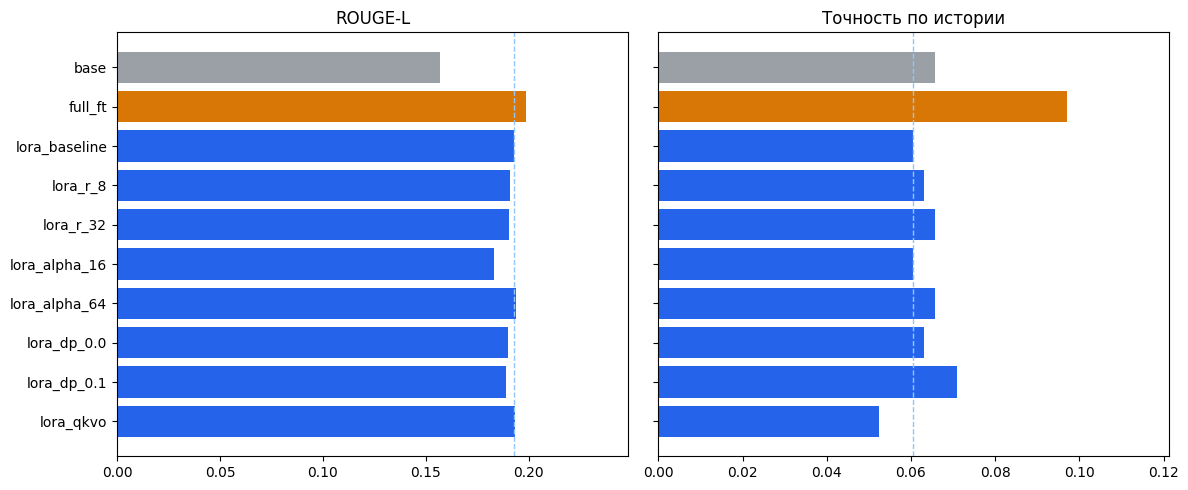

In [22]:
import matplotlib.pyplot as plt

order = [
    'base', 'full_ft', 'lora_baseline',
    'lora_r_8', 'lora_r_32',
    'lora_alpha_16', 'lora_alpha_64',
    'lora_dp_0.0', 'lora_dp_0.1', 'lora_qkvo',
]
plot_df = results.set_index('run').reindex(order)
colors = [
    '#9aa0a6' if run == 'base' else '#d97706' if run == 'full_ft' else '#2563eb'
    for run in plot_df.index
]

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, column, title in zip(
    axes,
    ['wikiwhy_rouge_l', 'mmlu_history_accuracy'],
    ['ROUGE-L', 'Точность по истории'],
):
    ax.barh(plot_df.index[::-1], plot_df[column][::-1], color=colors[::-1])
    ax.set_title(title)
    ax.set_xlim(0, plot_df[column].max() * 1.25)
    ax.axvline(plot_df.loc['lora_baseline', column], color='#93c5fd', linestyle='--', linewidth=1)
fig.tight_layout()
plt.show()

## Анализ четырёх параметров LoRA

Сравнение с `lora_baseline` (ROUGE-L 0.193, история 0.060, 2.18 млн параметров). Baseline обучен микробатчем 1, остальные LoRA — батчем 32, поэтому время и память baseline с ними не сравниваются. У батча 32 опыт занимает около 53 с и 21 ГБ.

| Параметр | Значения | Изменение ROUGE-L | Изменение history accuracy | Изменения качества и затрат |
|---|---|---|---|---|
| r | 8 и 32 | −0.002 и −0.003 | +0.003 и +0.005 | Качество то же. Параметров 1.09 млн и 4.36 млн. |
| lora_alpha | 16 и 64 | −0.010 и +0.001 | 0 и +0.005 | Падает только `alpha=16`. Число параметров не меняется. |
| lora_dropout | 0 и 0.1 | −0.003 и −0.004 | +0.003 и +0.011 | ROUGE-L чуть ниже. При 0.1 история 0.071, лучший результат LoRA. |
| target_modules | q, k, v, o | +0.001 | −0.008 | ROUGE-L тот же, история хуже. Параметров вдвое больше, 60 с. |

Кроме `alpha=16` сдвиги ROUGE-L меньше 0.005. На истории много ответов не в одну букву, 221–243 ошибки формата из 381. Устойчивой зависимости нет.

## Финальные выводы

Full FT поднимает ROUGE-L с 0.157 до 0.199 и точность по истории с 0.066 до 0.097. Обучаются все 1.54 млрд параметров, 638 с, пик 15.3 ГБ.

LoRA baseline даёт ROUGE-L 0.193 при 2.18 млн параметров, но историю не улучшает (0.060). Ни один вариант LoRA не догоняет Full FT по истории.

Из четырёх параметров заметен только `lora_alpha`: 16 снижает ROUGE-L на 0.01. Ранг, dropout и добавление `k_proj` с `o_proj` почти ничего не меняют.

Для ROUGE-L достаточно LoRA. Прирост на историческом экзамене даёт только Full FT.